# Active-set policies for Ramen (ImageNet-C, severity 5)

Ramen keeps a memory of past test images: each image's gradient is filed in the queue of its zero-shot class (75 slots per class, newest replaces oldest). For each new query it builds an **active set**, the memory entries whose gradients are averaged into one SignSGD step. This notebook compares three ways to pick that active set. The memory is the same under every policy; only the retrieval changes.

| # | policy (`src/methods/RamenPolicy.py`) | active set of a query | knob |
|---|---|---|---|
| 1 | `global_knn`: **top-k** | the k nearest images of the whole memory, from any class queue | k = 1, 10, 100, 1000, 5000 |
| 2 | `per_class`: **n images from each class** | the n nearest images from every non-empty class queue; each queue counts once | n = 1 (= Ramen), 3, 10, 75 (whole memory) |
| 3 | `zs_prob`: **zero-shot probabilities** | Ramen's set (n = 1 per class), each class queue weighted by the query's zero-shot probability softmax(logits / T) | T = 1, 3, 10 |

Each entry j also carries Ramen's weight exp(-H_j) (its zero-shot entropy; beta = 0 on ImageNet-C, so distance only selects and does not weight).

**Self-retrieval.** Ramen writes a batch into memory before retrieving, so the query itself is in memory at distance 0. Top-k with k = 1 is therefore per-sample adaptation (the query's own gradient only). The `self weight %` column tracks how much of each update is the query's own gradient.

**Note on "top-k".** An earlier experiment (`imagenetc_active_set.ipynb`) kept the top-m **zero-shot classes** instead of the top-k nearest images. Those cached runs are shown at the end of section 2 for comparison.

Setup: ViT-B/16, mixed stream of all 15 corruptions (75,000 images), batch 100, **seed 0 only**. Before calling a policy better than Ramen, it needs seeds 0-4. The ImageNet-C noise floor (2 x Ramen's range over seeds) is 0.54 points. Runs: `active_set_policies.py run` (about 8-12 min per run on one GPU). This notebook runs on CPU from the cached results.

In [1]:
%load_ext autoreload
%autoreload 2
import os
os.environ['CUDA_VISIBLE_DEVICES'] = ''  # everything below is offline

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from ramen_analysis import CATEGORICAL, TEXT_2, MUTED
from active_set_policies import (VARIANTS, FAMILY_LABEL, KNOB, experiment, outcome_table, ActiveSets)

pd.set_option('display.width', 200)

/home/priyank1/miniconda3/envs/RAMEN/lib/python3.10/site-packages/tqdm/auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


In [2]:
exp = experiment('ImageNetC5K', device='cpu').load()
acc = exp.evaluate()                    # NoAdapt + Ramen (cached)
for name, (_, _, cfg) in VARIANTS.items():
    exp.run('RamenPolicy', name=name, cfg=cfg)   # cached by active_set_policies.py run
OLD = {'active_top2': 2, 'active_top5': 5, 'active_top20': 20, 'active_top100': 100, 'active_prob_T3': 3}
for name in OLD:
    exp.run('RamenActive', name=name)   # cached by imagenetc_active_set.ipynb

ImageNetC5K: 15 corruptions x 5000 images, 1000 classes, model=clip_vitbase16, mode=mixed
NoAdapt: loaded cached results from /home/priyank1/Projects/Ramen/new_experiments/results/ImageNetC5K_clip_vitbase16_mixed_nall_bs100_s0_NoAdapt.pkl


Ramen: loaded cached results from /home/priyank1/Projects/Ramen/new_experiments/results/ImageNetC5K_clip_vitbase16_mixed_nall_bs100_s0_Ramen.pkl
policy_global_k1: loaded cached results from /home/priyank1/Projects/Ramen/new_experiments/results/ImageNetC5K_clip_vitbase16_mixed_nall_bs100_s0_policy_global_k1.pkl
policy_global_k10: loaded cached results from /home/priyank1/Projects/Ramen/new_experiments/results/ImageNetC5K_clip_vitbase16_mixed_nall_bs100_s0_policy_global_k10.pkl
policy_global_k100: loaded cached results from /home/priyank1/Projects/Ramen/new_experiments/results/ImageNetC5K_clip_vitbase16_mixed_nall_bs100_s0_policy_global_k100.pkl
policy_global_k1000: loaded cached results from /home/priyank1/Projects/Ramen/new_experiments/results/ImageNetC5K_clip_vitbase16_mixed_nall_bs100_s0_policy_global_k1000.pkl
policy_global_k5000: loaded cached results from /home/priyank1/Projects/Ramen/new_experiments/results/ImageNetC5K_clip_vitbase16_mixed_nall_bs100_s0_policy_global_k5000.pkl


policy_class_n1: loaded cached results from /home/priyank1/Projects/Ramen/new_experiments/results/ImageNetC5K_clip_vitbase16_mixed_nall_bs100_s0_policy_class_n1.pkl
policy_class_n3: loaded cached results from /home/priyank1/Projects/Ramen/new_experiments/results/ImageNetC5K_clip_vitbase16_mixed_nall_bs100_s0_policy_class_n3.pkl
policy_class_n10: loaded cached results from /home/priyank1/Projects/Ramen/new_experiments/results/ImageNetC5K_clip_vitbase16_mixed_nall_bs100_s0_policy_class_n10.pkl
policy_class_n75: loaded cached results from /home/priyank1/Projects/Ramen/new_experiments/results/ImageNetC5K_clip_vitbase16_mixed_nall_bs100_s0_policy_class_n75.pkl
policy_zs_T1: loaded cached results from /home/priyank1/Projects/Ramen/new_experiments/results/ImageNetC5K_clip_vitbase16_mixed_nall_bs100_s0_policy_zs_T1.pkl
policy_zs_T3: loaded cached results from /home/priyank1/Projects/Ramen/new_experiments/results/ImageNetC5K_clip_vitbase16_mixed_nall_bs100_s0_policy_zs_T3.pkl
policy_zs_T10: loa

active_top2: loaded cached results from /home/priyank1/Projects/Ramen/new_experiments/results/ImageNetC5K_clip_vitbase16_mixed_nall_bs100_s0_active_top2.pkl
active_top5: loaded cached results from /home/priyank1/Projects/Ramen/new_experiments/results/ImageNetC5K_clip_vitbase16_mixed_nall_bs100_s0_active_top5.pkl
active_top20: loaded cached results from /home/priyank1/Projects/Ramen/new_experiments/results/ImageNetC5K_clip_vitbase16_mixed_nall_bs100_s0_active_top20.pkl
active_top100: loaded cached results from /home/priyank1/Projects/Ramen/new_experiments/results/ImageNetC5K_clip_vitbase16_mixed_nall_bs100_s0_active_top100.pkl
active_prob_T3: loaded cached results from /home/priyank1/Projects/Ramen/new_experiments/results/ImageNetC5K_clip_vitbase16_mixed_nall_bs100_s0_active_prob_T3.pkl


## 1. Sanity checks
- `per_class n=1` is Ramen's rule computed by the new code (fp32 matrix products instead of Ramen's fp16 gather-and-sum). It should agree with Ramen on nearly every prediction; SignSGD flips the sign of gradient components that round differently near zero.
- `zs_prob T=3` should agree with the earlier RamenActive `prob T=3` run.

In [3]:
same = lambda a, b: (exp.results[a].pred.values == exp.results[b].pred.values).mean() * 100
print(f"per_class n=1 vs Ramen:              {same('policy_class_n1', 'Ramen'):.2f}% same predictions")
print(f"zs_prob T=3 vs RamenActive prob T=3: {same('policy_zs_T3', 'active_prob_T3'):.2f}% same predictions")

per_class n=1 vs Ramen:              99.71% same predictions
zs_prob T=3 vs RamenActive prob T=3: 99.76% same predictions


## 2. Outcomes
- `accuracy %`: mean over the 15 corruptions (the paper's metric). `vs Ramen`: difference in points.
- `fixed %` / `broken %`: share of all samples that zero-shot got wrong and the policy got right / zero-shot got right and the policy got wrong.
- `active entries`: mean number of memory entries in a query's active set.
- `self weight %`: mean share of the update that is the query's own gradient.

In [4]:
names = list(VARIANTS)
table = outcome_table(exp, names)
table.style.format({c: '{:.2f}' for c in table.columns if c not in ('policy', 'knob')}, na_rep='') \
     .background_gradient(subset=['vs Ramen'], cmap='RdBu', vmin=-3, vmax=3)

,policy,knob,accuracy %,vs Ramen,fixed %,broken %,same pred as Ramen %,active entries (mean),self weight %
NoAdapt,reference,,27.29,-5.79,0.00,0.00,47.49,,
Ramen,reference,,33.08,0.00,9.61,3.82,100.00,,
policy_global_k1,1. top-k nearest images (whole memory),k=1,30.08,-3.00,4.61,1.82,50.18,1.00,99.29
policy_global_k10,1. top-k nearest images (whole memory),k=10,31.06,-2.02,6.43,2.66,51.68,10.00,13.78
policy_global_k100,1. top-k nearest images (whole memory),k=100,32.22,-0.86,8.02,3.09,58.85,100.00,1.02
policy_global_k1000,1. top-k nearest images (whole memory),k=1000,33.34,0.26,9.57,3.52,71.01,994.00,0.04
policy_global_k5000,1. top-k nearest images (whole memory),k=5000,32.66,-0.42,9.21,3.84,76.67,4833.40,0.00
policy_class_n1,2. n images from each class,n=1,33.09,0.01,9.61,3.82,99.71,973.94,0.06
policy_class_n3,2. n images from each class,n=3,32.84,-0.23,9.45,3.89,82.61,2847.75,0.01
policy_class_n10,2. n images from each class,n=10,31.84,-1.24,8.49,3.95,75.24,8642.96,0.00


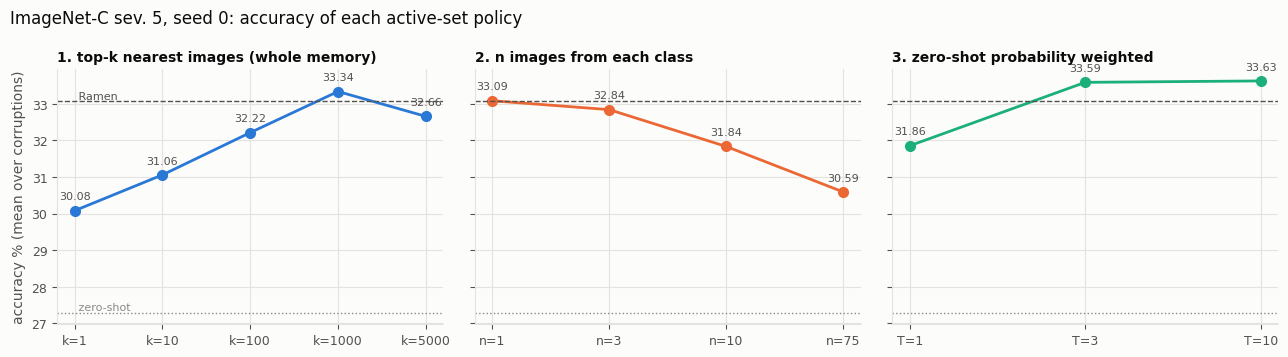

In [5]:
ramen_acc = table.loc['Ramen', 'accuracy %']
zs_acc = table.loc['NoAdapt', 'accuracy %']
fig, axes = plt.subplots(1, 3, figsize=(13, 3.6), sharey=True)
for ax, (family, color) in zip(axes, zip(FAMILY_LABEL, CATEGORICAL)):
    rows = [(VARIANTS[n][1], table.loc[n, 'accuracy %']) for n in names if VARIANTS[n][0] == family]
    x, y = zip(*rows)
    ax.plot(range(len(x)), y, '-o', color=color, lw=2, ms=7)
    for i, v in enumerate(y):
        ax.annotate(f'{v:.2f}', (i, v), textcoords='offset points', xytext=(0, 8), ha='center', fontsize=8, color=TEXT_2)
    ax.axhline(ramen_acc, color=TEXT_2, lw=1, ls='--')
    ax.axhline(zs_acc, color=MUTED, lw=1, ls=':')
    ax.set_xticks(range(len(x)), [f'{KNOB[family]}={v}' for v in x])
    ax.set_title(FAMILY_LABEL[family], fontsize=10)
axes[0].set_ylabel('accuracy % (mean over corruptions)')
axes[0].text(0, ramen_acc, ' Ramen', va='bottom', fontsize=8, color=TEXT_2)
axes[0].text(0, zs_acc, ' zero-shot', va='bottom', fontsize=8, color=MUTED)
fig.suptitle('ImageNet-C sev. 5, seed 0: accuracy of each active-set policy', x=0.01, ha='left')
fig.tight_layout()

Accuracy per corruption (%), with the best setting of each policy (and Ramen).

In [6]:
best = {f: max((n for n in names if VARIANTS[n][0] == f), key=lambda n: table.loc[n, 'accuracy %'])
        for f in FAMILY_LABEL}
cols = ['NoAdapt', 'Ramen', *dict.fromkeys(best.values())]
per_domain = pd.DataFrame({n: exp.results[n].groupby('domain', observed=True).correct.mean() * 100 for n in cols})
per_domain.loc['average'] = per_domain.mean()
print('best per policy:', best)
per_domain.round(2)

best per policy: {'global_knn': 'policy_global_k1000', 'per_class': 'policy_class_n1', 'zs_prob': 'policy_zs_T10'}


,NoAdapt,Ramen,policy_global_k1000,policy_class_n1,policy_zs_T10
domain,,,,,
gaussian_noise,15.00,22.24,23.46,22.32,22.90
shot_noise,16.88,23.18,24.90,23.16,24.10
impulse_noise,15.36,23.64,23.68,23.64,24.12
defocus_blur,25.68,28.52,29.28,28.56,29.32
glass_blur,16.90,24.20,24.42,24.20,24.82
motion_blur,26.82,32.88,33.58,32.84,33.78
zoom_blur,24.58,29.76,29.10,29.78,30.06
snow,34.00,37.40,37.98,37.40,37.80
frost,33.02,34.98,35.18,34.98,36.06


For comparison, the other reading of "top-k": keep only the query's top-m **zero-shot classes** (each kept class contributes its nearest entry). These are cached RamenActive runs from `imagenetc_active_set.ipynb`.

In [7]:
pd.DataFrame({f'top-{m} zero-shot classes' if 'top' in n else f'zero-shot prob T={m} (RamenActive)':
              {'accuracy %': exp.results[n].groupby('domain_idx').correct.mean().mean() * 100}
              for n, m in OLD.items()}).T.assign(**{'vs Ramen': lambda t: t['accuracy %'] - ramen_acc}).round(2)

,accuracy %,vs Ramen
top-2 zero-shot classes,29.82,-3.26
top-5 zero-shot classes,29.92,-3.16
top-20 zero-shot classes,31.09,-1.98
top-100 zero-shot classes,32.73,-0.35
zero-shot prob T=3 (RamenActive),33.59,0.51


## 3. Active sets on confused test cases
The memory is the same under every policy (writes do not depend on retrieval), so `ActiveSets` replays it offline (`CacheReplay` in `ramen_examples.py`) and scores the entries with the zero-shot features, as `RamenPolicy` does on the GPU. First, a check that the offline active sets match what the GPU runs logged (their 8 highest-weight entries). Small gaps come from fp16 zero-shot features (NoAdapt run) vs the features inside each run.

In [8]:
ex = ActiveSets(exp)
ex.validate(names, n=100)

ImageNetC5K: 15 corruptions x 5000 images, 1000 classes, model=clip_vitbase16, mode=mixed


,top-1 entry identical %,top-8 overlap %
policy_global_k1,100.0,100.0
policy_global_k10,98.0,98.8
policy_global_k100,100.0,98.6
policy_global_k1000,97.0,97.8
policy_global_k5000,100.0,98.1
policy_class_n1,97.0,97.6
policy_class_n3,95.0,98.0
policy_class_n10,100.0,98.2
policy_class_n75,100.0,98.6
policy_zs_T1,99.0,99.0


A **confused** test case: CLIP's zero-shot top-1 is wrong and the true class is its runner-up (CLIP hesitates between two classes), after the first 20% of the stream so the memory is warm. How often does each policy resolve the confusion?

In [9]:
conf = ex.confused_cases(['Ramen', *names])
print(f'{len(conf):,} confused cases ({len(conf) / len(ex.df) * 100:.1f}% of the stream)')
(conf[['Ramen', *names]].mean() * 100).round(2).rename('% of confused cases resolved').to_frame().T

5,930 confused cases (7.9% of the stream)


,Ramen,policy_global_k1,policy_global_k10,policy_global_k100,policy_global_k1000,policy_global_k5000,policy_class_n1,policy_class_n3,policy_class_n10,policy_class_n75,policy_zs_T1,policy_zs_T3,policy_zs_T10
% of confused cases resolved,36.42,23.32,30.64,35.19,37.77,36.34,36.42,36.24,34.99,31.26,33.12,35.85,36.8


What the active sets look like on confused cases, averaged over 200 random ones (seed 0):
- `entries`, `queues`: size of the active set and how many class queues it draws from,
- `weight on true class images %`: share of the update from images whose **true** class is the query's true class (labels are hidden from Ramen; this is the oracle view),
- `weight filed as true class %` / `as zero-shot class %`: share from the queue of the query's true class / of its wrong zero-shot class,
- `self weight %`, `weight from same corruption %`.

In [10]:
shown = ['policy_global_k10', 'policy_global_k1000', 'policy_class_n1', 'policy_class_n10', 'policy_zs_T3']
sample = conf.sample(200, random_state=0).position.sort_values().values
ex.active_set_profile(sample, shown)

,entries,queues,weight on true class images %,weight filed as true class %,weight filed as zero-shot class %,self weight %,weight from same corruption %,accuracy on these %
run,,,,,,,,
policy_global_k10,10.00,7.30,34.71,11.08,30.97,14.47,71.99,29.0
policy_global_k1000,1000.00,335.89,3.89,3.12,3.54,0.24,45.32,36.0
policy_class_n1,996.38,996.38,0.79,0.32,0.30,0.30,44.86,32.5
policy_class_n10,9521.42,996.38,0.28,0.19,0.18,0.02,20.16,32.5
policy_zs_T3,996.38,996.38,12.63,4.76,7.59,7.59,51.49,32.5


### Individual confused cases
Cases where the policies **disagree** (some resolve the confusion, some do not), drawn at random with a fixed seed (not hand-picked). Each row is one policy. On the left: its prediction and a summary of its whole active set. Tiles: the 8 highest-weight entries, with the class queue each was filed under and its share of the update. Green frame = the image's true class is the query's true class; red frame = it is the query's wrong zero-shot class.

Policies shown: top-k with k = 10 and k = 1000, n per class with n = 1 (Ramen) and n = 10, zero-shot weighting with T = 3.

In [11]:
disagree = conf[(conf[shown].sum(axis=1) > 0) & (conf[shown].sum(axis=1) < len(shown))]
print(f'{len(disagree):,} confused cases on which these policies disagree')
picks = disagree.sample(4, random_state=0).sort_values('position')
picks[['position', 'domain', 'zs_true_p']].assign(
    true=[ex.classes[c] for c in picks.label], zero_shot=[ex.classes[c] for c in picks.zs_pred],
    **{n: picks[n].map({True: 'right', False: 'wrong'}) for n in shown})

2,467 confused cases on which these policies disagree


,position,domain,zs_true_p,true,zero_shot,policy_global_k10,policy_global_k1000,policy_class_n1,policy_class_n10,policy_zs_T3
28693,28693,jpeg_compression,0.171082,coyote,dhole,wrong,wrong,right,right,wrong
31935,31935,motion_blur,0.226164,snowplow,snowmobile,wrong,right,wrong,wrong,wrong
41752,41752,shot_noise,0.116287,tripod,television,wrong,right,right,right,right
58398,58398,motion_blur,0.152969,cleaver,frying pan,right,wrong,wrong,wrong,right


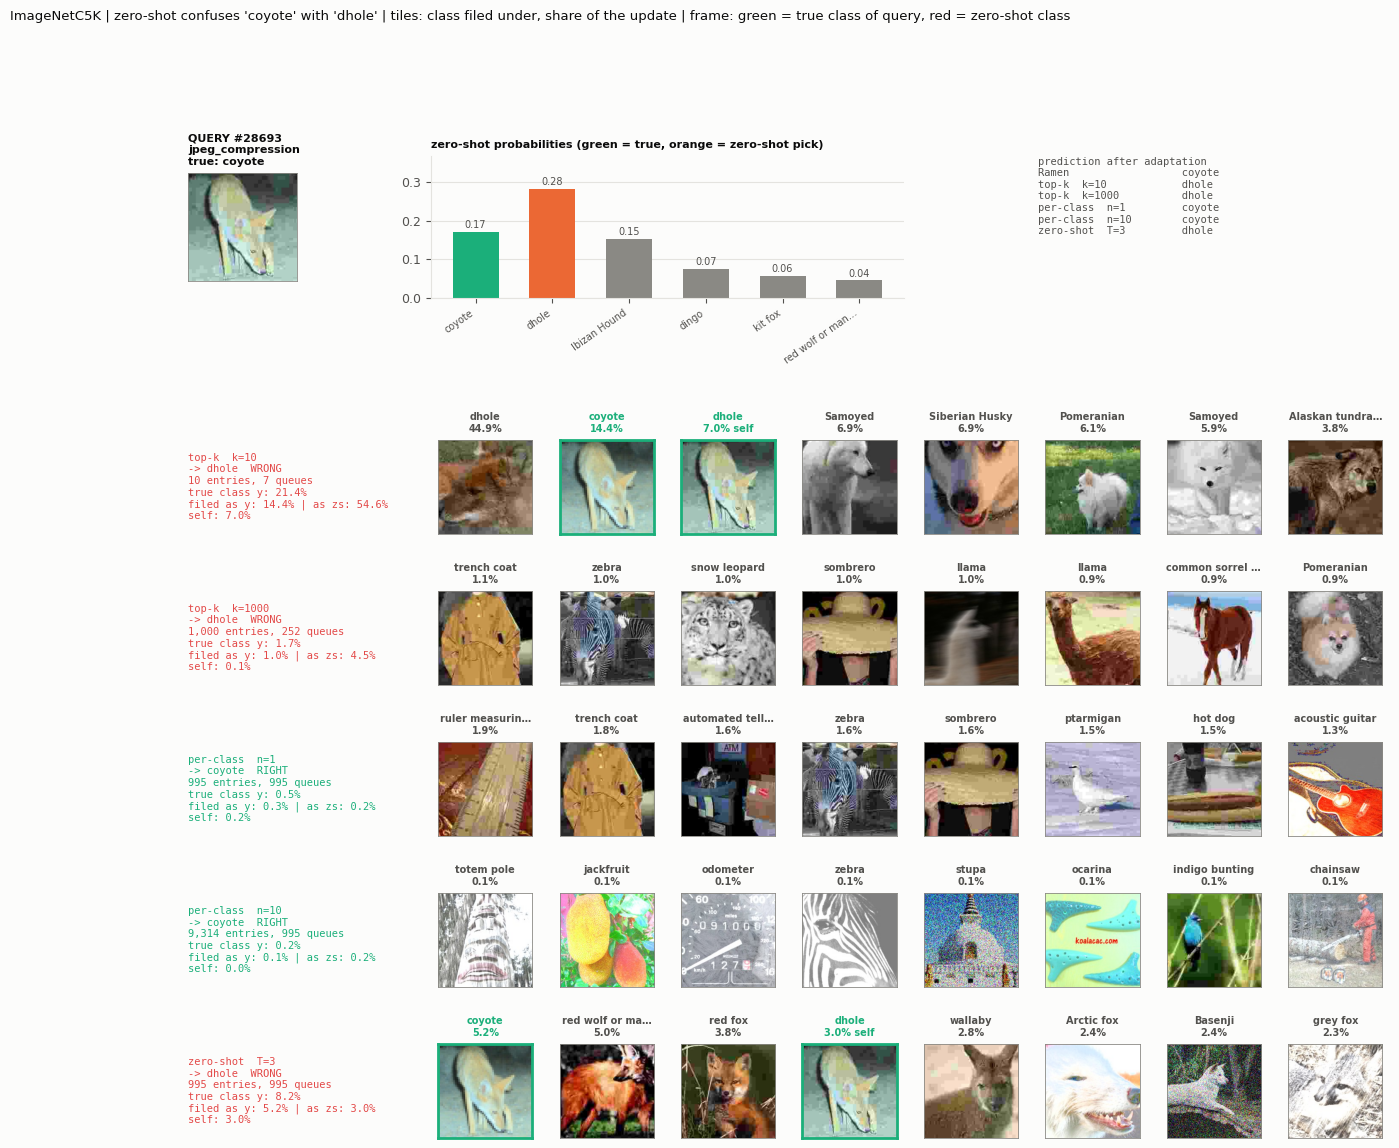

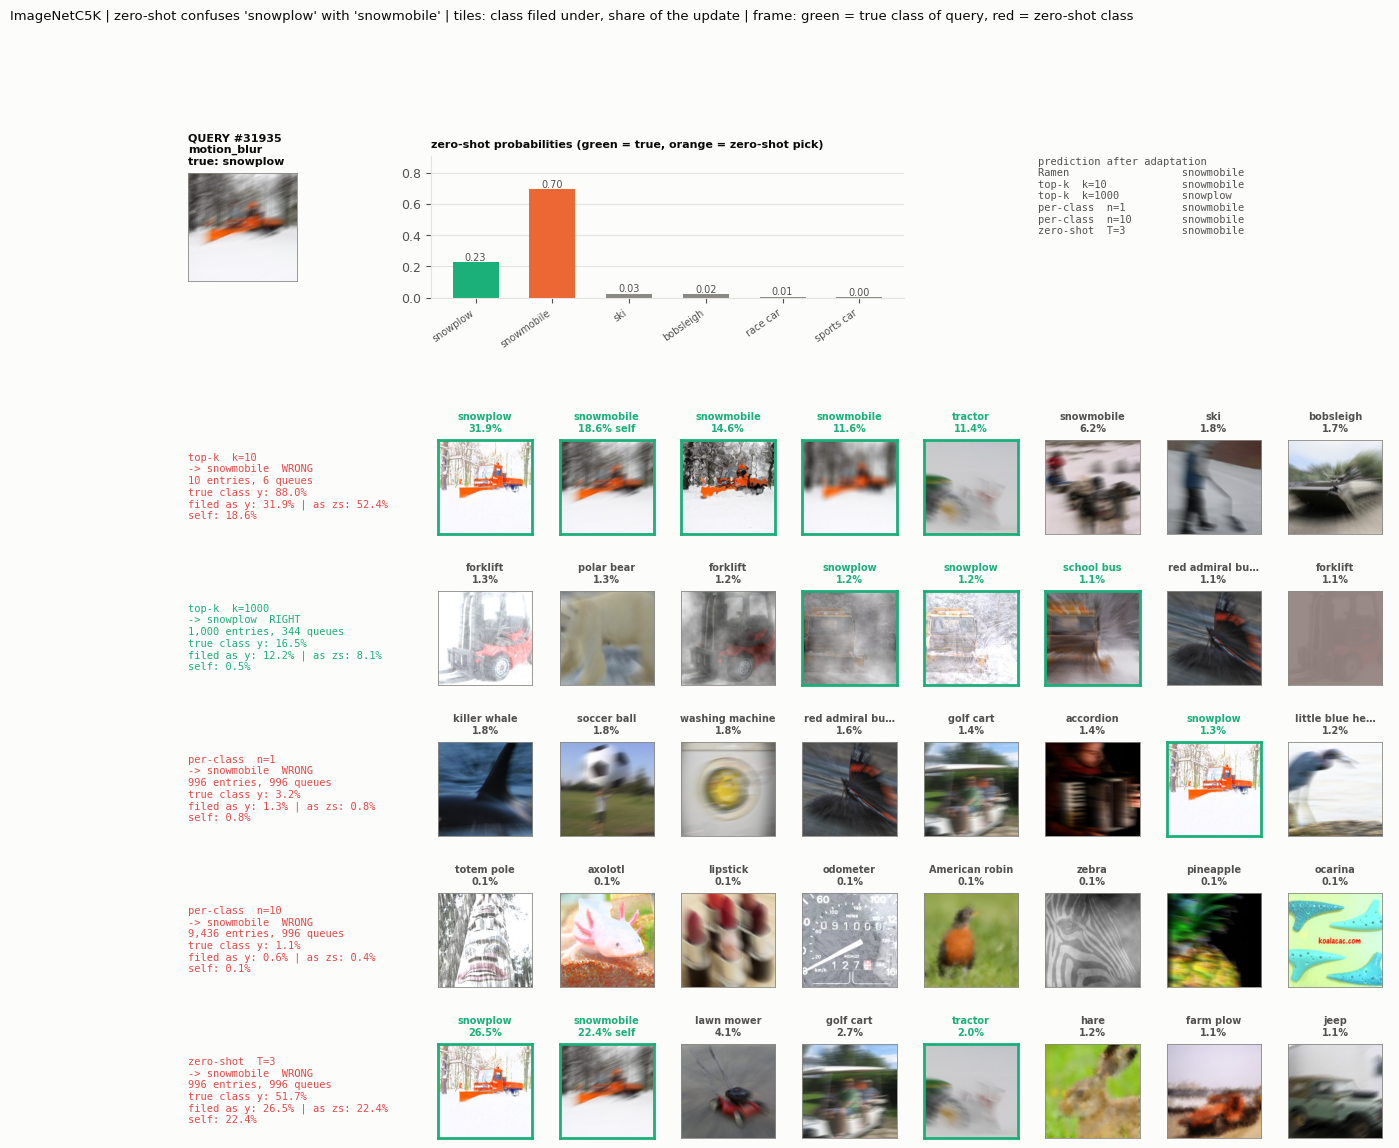

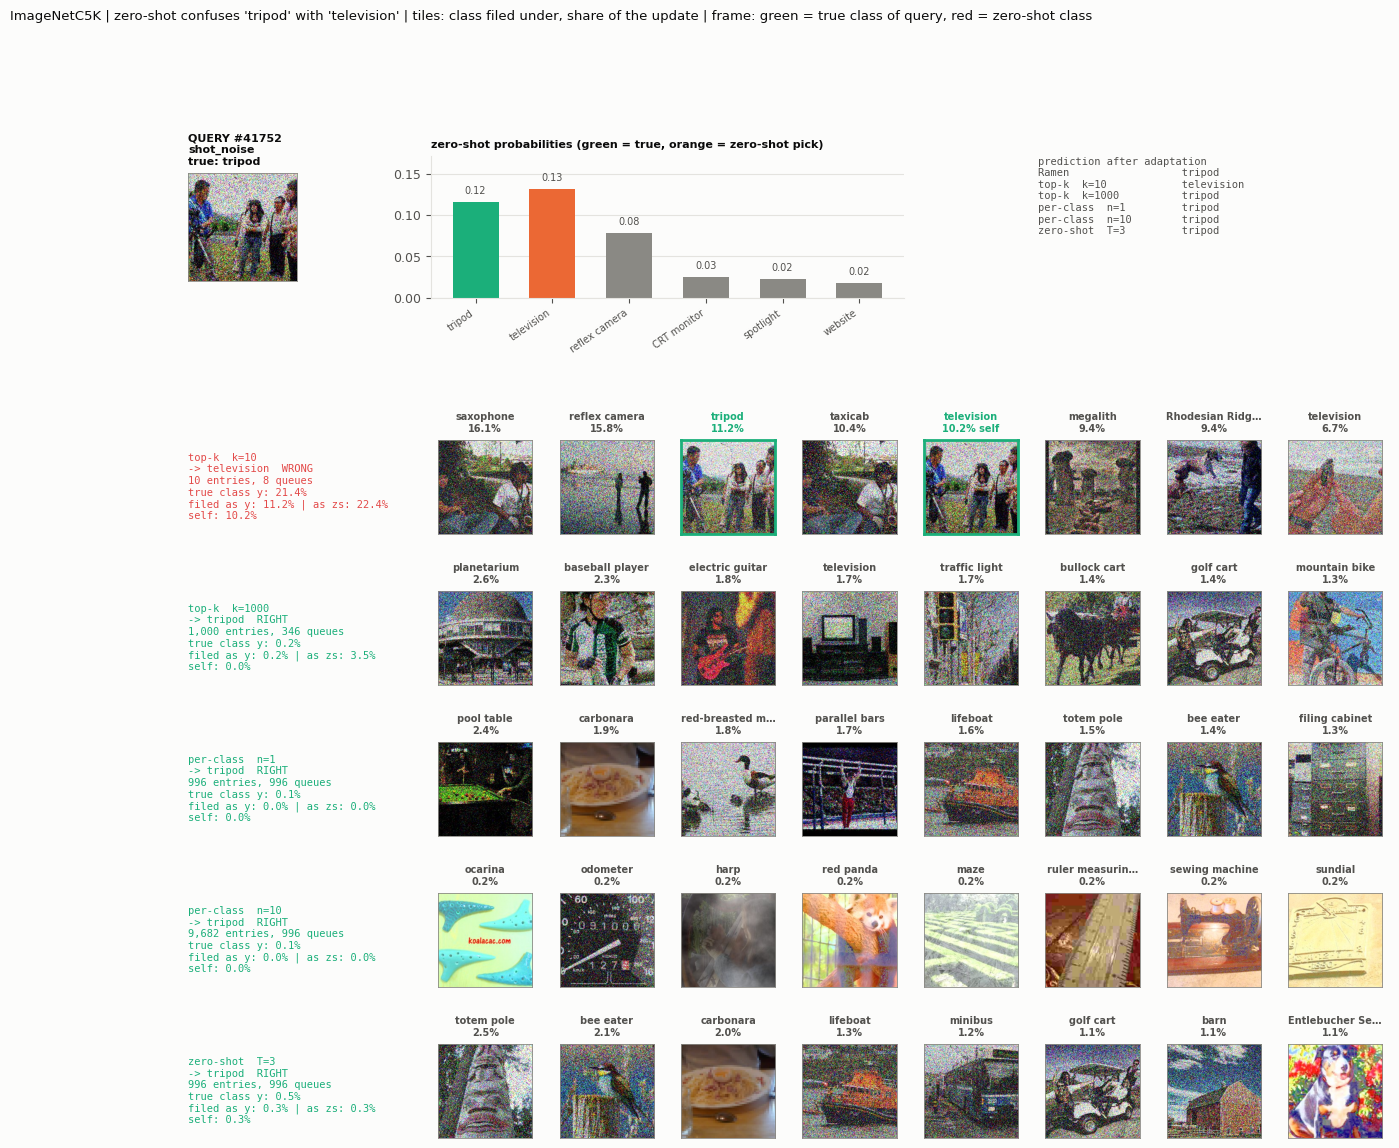

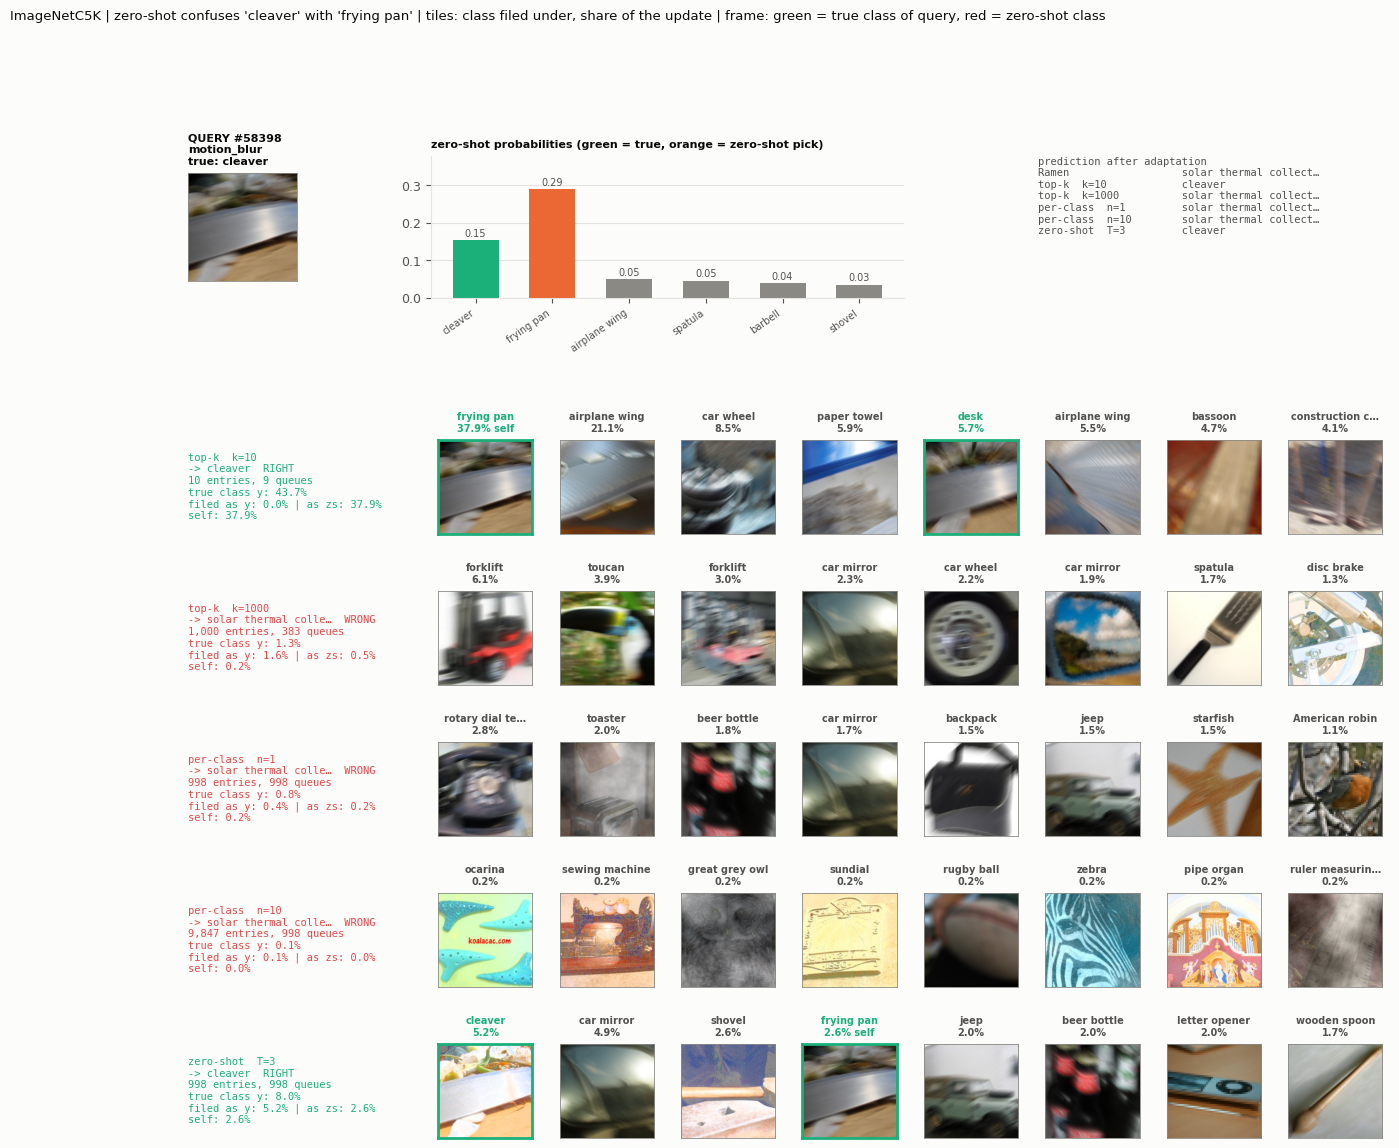

In [12]:
snaps = ex.replay.snapshots(list(picks.position))
for p in picks.position:
    ex.show_policies(p, shown, snap=snaps[p])
    plt.show()

And one confused case that **every** policy gets wrong, for contrast.

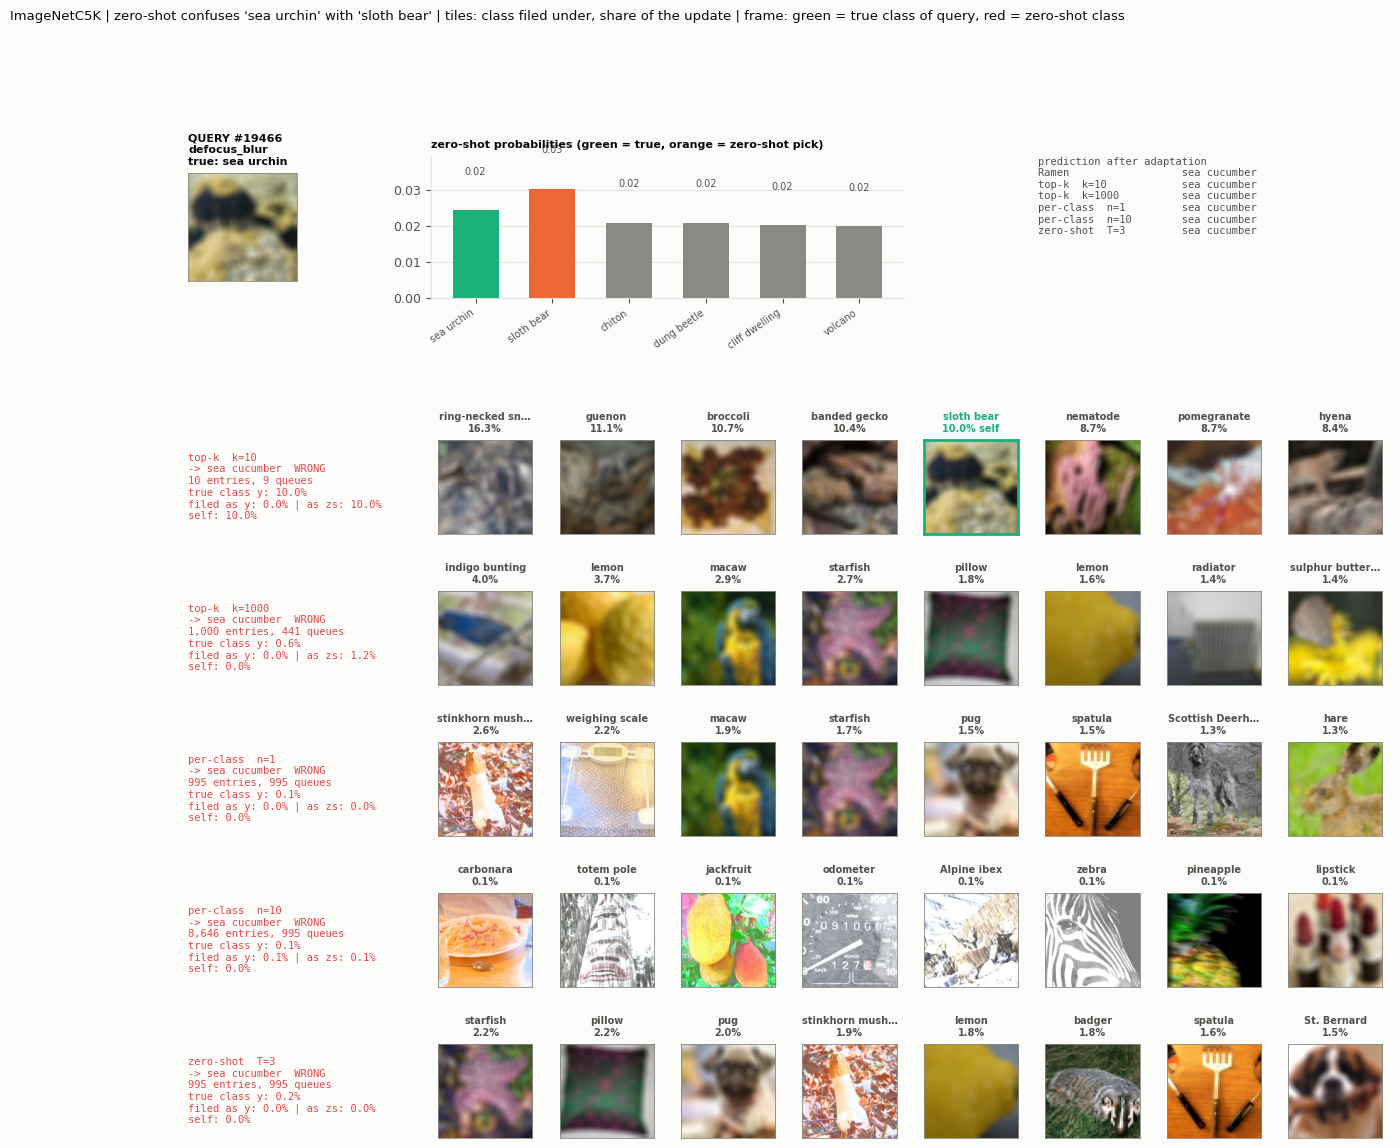

In [13]:
all_wrong = conf[conf[shown].sum(axis=1) == 0].sample(1, random_state=0).position.values[0]
ex.show_policies(all_wrong, shown);

## Notes
- Seed 0 only. A policy that beats Ramen here needs seeds 0-4 (`active_seeds.py` pattern) and must clear the 0.54-point ImageNet-C noise floor.
- ImageNet-C is 75,000 samples, so Ramen's fp16 priority counter saturates after 65,520 and full queues stop updating in the last ~13% of the stream (see the findings memo). This affects every policy the same way because they share the memory.
- `global_knn` with small k leans on the query's own gradient (k = 1 is per-sample adaptation); compare `self weight %` with accuracy.
- Any query can be shown with `ex.show_policies(position, [run names])`; `ex.policy_active_set(position, snap, policy, knob)` returns the full active set as a table.